# 02 · Feature engineering

## Turning each clip into numbers, and what those numbers carry

`01_EDA` ended with four things settled and one open question:

- **Settled:** we split by speaker; the preprocessing chain is fixed; loudness belongs to the emotion; pitch belongs
  to the speaker, so pitch is expressed per speaker.
- **Open:** about half of every 3.5 s window is zero padding, and the share differs by emotion.

This notebook builds the feature table and settles that open question first (§2). It then asks what the 512
features actually carry (§3). The hypotheses continue the numbering from `01_EDA` (H12 onwards), with the same
pattern: hypothesis → evidence → verdict → "So we …".

**Data used.** The **dev speakers only** (1,080 clips, 18 speakers). Every analysis cell asserts that no held-out
speaker is present.

**Runtime.**
- `RUN_HEAVY = False` (default): about 20 seconds. The window test reads its saved results table.
- `RUN_HEAVY = True`: re-extracts the feature table and rebuilds all 12 window-test feature sets. About 3½ minutes on
  an 8-core laptop.

**Writes:**
- `outputs/features/`: `features.parquet`, `feature_manifest.json`
- `outputs/tables/`: `window_test.csv`, `eta_squared.csv`, `eta_by_group.csv`, `redundancy.json`, `silhouette.json`,
  `confusion_pairs.csv`, `duplicate_check.json`
- `outputs/figures/`: F07, F07a, F07b, F07c

In [1]:
# Setup: shared helpers, libraries, and the switch for heavy steps.
import sys
from pathlib import Path

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import json

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import audio_utils as U
import features as F
import speaker_split as S

# False: read saved results for the slow steps (about 20 seconds).
# True: rebuild everything from the audio (about 3.5 min, 8 cores).
RUN_HEAVY = False

SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    '''Store one hypothesis result and print its verdict.'''
    SUMMARY.append({"H": h, "hypothesis": claim, "verdict": verdict,
                    "evidence": evidence, "so we": decision})
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


# The label index and the dev-speaker mask used by every cell below.
index = U.load_index()
dev = S.dev_mask(index)
S.assert_no_test_speakers(index.loc[dev, "filepath"], "dev set")
n_dev, n_spk = int(dev.sum()), index.loc[dev, "speaker"].nunique()
DEV_SOURCE = (f"Source: own analysis, dev speakers (n={n_dev:,} clips, "
              f"{n_spk} speakers)")
print(f"dev set: {n_dev:,} clips from {n_spk} speakers; "
      f"RUN_HEAVY = {RUN_HEAVY}")


dev set: 1,080 clips from 18 speakers; RUN_HEAVY = False


---
## 1 · From clips to numbers

A classical model cannot read a waveform directly. Each clip is summarised as a fixed set of numbers: its
**features**. `shared/features.py` computes 512 of them per clip, in five groups. The table below is built from the
extraction code itself, not from memory.

In [2]:
# Build the feature table (RUN_HEAVY) or load the saved one. Rows are
# in label-index order; the check below makes sure of it.
feat_path = U.features_dir() / "features.parquet"
if RUN_HEAVY or not feat_path.exists():
    feats, manifest = F.extract_all()
else:
    feats = pd.read_parquet(feat_path)
    manifest = json.loads((U.features_dir()
                           / "feature_manifest.json").read_text())
    print("[cache hit] loaded outputs/features/features.parquet")
assert (feats["filepath"].values == index["filepath"].values).all()

cols = [c for c in feats.columns if c not in ("filepath", "emotion")]
groups = pd.Series([F.feature_group(c) for c in cols], index=cols)
overview = pd.DataFrame({
    "columns": groups.value_counts(),
    "example columns": groups.groupby(groups).apply(
        lambda s: ", ".join(s.index[:3]) + ", ..."),
}).reindex(["energy", "pitch", "mfcc", "spectral", "voice_quality"])
print(f"{len(feats)} clips x {len(cols)} features")
print(f"window {manifest['clip_seconds']} s, trim {manifest['trim_top_db']}"
      f" dB, statistics over speech frames only: {manifest['masked']}")
overview

[cache hit] loaded outputs/features/features.parquet
1440 clips x 512 features
window 3.5 s, trim 30.0 dB, statistics over speech frames only: True


,columns,example columns
energy,5,"energy_rms, energy_frame_rms_mean, energy_fram..."
pitch,5,"f0_mean_speaker_z, f0_std_speaker_z, f0_range_..."
mfcc,480,"mfcc_00_mean, mfcc_00_std, mfcc_00_min, ..."
spectral,20,"centroid_mean, centroid_std, centroid_min, ..."
voice_quality,2,"jitter, shimmer, ..."


### What the five groups measure

| Group | Columns | In plain words | How it is computed | Motivated by |
|---|---|---|---|---|
| **Energy** | 5 | How loud the speech is, and how the loudness moves over the utterance | RMS of the trimmed speech, plus the mean / std / min / max of frame-by-frame RMS | H5, H10, H11: loudness tracks emotion, not speaker |
| **Pitch** | 5 | How high the voice is *relative to that speaker's own average*, how much it varies, its range and whether it rises or falls; plus the share of frames that are voiced | pyin F0 over voiced frames; mean, std, range and slope **z-scored within each speaker**; voiced fraction as is | H11: raw pitch mostly identifies the speaker |
| **MFCC** | 480 | The timbre, or "colour", of the voice: the shape of the spectrum the vocal tract produces, plus how fast it changes (delta) and how that change accelerates (delta-delta) | 40 coefficients × 3 series × 4 statistics (mean, std, min, max) | standard compact description of speech |
| **Spectral** | 20 | Brightness (centroid), where 85% of the energy lies (roll-off), spread (bandwidth), tone vs noise (flatness), and zero-crossing rate | 5 descriptors × 4 statistics | tense or breathy voices shift these |
| **Voice quality** | 2 | Jitter: how unsteady the pitch is. Shimmer: how unsteady the loudness is | frame-to-frame change relative to the mean (a frame-level approximation) | strain and trembling in the voice |

Three engineering choices come straight from `01_EDA`:
- Energy, pitch and voice quality are measured on the **trimmed speech**, so neither silence nor padding enters them.
- Pitch is **z-scored within each speaker** (H11). **[ASSUMPTION]** In deployment this needs a pitch baseline for
  each caller. It uses no emotion labels.
- MFCC and spectral statistics are computed over **speech frames only**. That choice is not assumed: the next
  section tests it.

---
## 2 · Does the padding hurt, and does the window matter?

A mean or standard deviation of MFCCs taken over the 3.5 s window includes every zero-padded frame. On average that
is 47% of the window, more for some emotions than others (H9). Three hypotheses are tested together, on one grid of
12 configurations:

| Setting | Values |
|---|---|
| Window length | 2.5 s, 3.0 s, 3.5 s |
| Silence trim | 30 dB, 40 dB below the clip's peak |
| MFCC/spectral statistics over | the whole window including padding, **or** speech frames only |

Everything else is held fixed. That includes the energy, pitch and voice-quality blocks, which are always measured
on trimmed speech. So the only thing that changes between rows is how the audio is prepared.

Each configuration is scored with two untuned models, class-balanced logistic regression and an RBF support vector
machine. Scoring uses **6-fold cross-validation that holds out 3 whole speakers per fold**, with the scaler fitted
inside each fold. The result is macro-F1, mean ± SD over the 6 folds.

In [3]:
# Cross-validation, written out so the leakage rules are visible:
# folds hold out whole speakers, and the scaler is fitted on the
# training speakers of each fold only.
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

MODELS = {
    "logreg": LogisticRegression(max_iter=2000, class_weight="balanced",
                                 random_state=U.SEED),
    "svc": SVC(kernel="rbf", class_weight="balanced", probability=True,
               random_state=U.SEED),
}


def dev_matrix(table):
    '''Dev rows of a feature table -> X, y, speaker groups, columns.'''
    names = [c for c in table.columns if c not in ("filepath", "emotion")]
    X = table.loc[dev, names].astype(np.float64).values
    y = index.loc[dev, "emotion"].values
    g = index.loc[dev, "speaker"].astype(int).values
    S.assert_no_test_speakers(table.loc[dev, "filepath"], "features")
    return X, y, g, names


def grouped_cv_macro_f1(estimator, X, y, g):
    '''Macro-F1 of each of the 6 speaker-grouped folds.'''
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    scores = []
    for tr, va in S.outer_splits("grouped", X, y, g):
        assert not set(g[tr]) & set(g[va])  # no speaker on both sides
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("clf", clone(estimator))])
        pipe.fit(X[tr], y[tr])
        proba = pipe.predict_proba(X[va])
        pred = pipe.classes_[proba.argmax(axis=1)]
        scores.append(f1_score(y[va], pred, average="macro",
                               labels=U.EMOTION_ORDER, zero_division=0))
    return scores

In [4]:
# The 12-configuration grid. With RUN_HEAVY each configuration's
# features are extracted into cache/window_test/ and scored; otherwise
# the saved results table is read.
WINDOWS, TOP_DBS = [2.5, 3.0, 3.5], [30.0, 40.0]
grid_path = U.tables_dir() / "window_test.csv"

if RUN_HEAVY:
    grid_dir = U.cache_dir() / "window_test"
    grid_dir.mkdir(exist_ok=True)
    rows = []
    for top_db in TOP_DBS:
        speech = F.trim_block(top_db).loc[dev, "trimmed_sec"].values
        for w in WINDOWS:
            for masked in (False, True):
                tag = f"w{w}_t{int(top_db)}_{'mask' if masked else 'pad'}"
                path = grid_dir / f"feat_{tag}.parquet"
                if not path.exists():
                    F.extract_all(w, top_db, masked, out_path=path,
                                  verbose=False)
                X, y, g, _ = dev_matrix(pd.read_parquet(path))
                res = {m: grouped_cv_macro_f1(est, X, y, g)
                       for m, est in MODELS.items()}
                pad = np.clip(1 - speech / w, 0, 1)
                row = {"window_s": w, "top_db": int(top_db),
                       "stats_over": ("speech only" if masked
                                      else "window incl. padding"),
                       "median_speech_s": round(float(np.median(speech)),
                                                3),
                       "mean_padding_pct": round(100 * pad.mean(), 1),
                       "clips_cropped": int((speech > w).sum()),
                       "pct_cropped": round(100 * (speech > w).mean(), 1)}
                for m, sc in res.items():
                    row[f"{m}_macro_f1_mean"] = round(float(np.mean(sc)), 4)
                    row[f"{m}_macro_f1_sd"] = round(
                        float(np.std(sc, ddof=1)), 4)
                for m, sc in res.items():
                    row[f"{m}_folds"] = " ".join(f"{s:.4f}" for s in sc)
                rows.append(row)
                print(f"{tag:<14} logreg {row['logreg_macro_f1_mean']:.4f}"
                      f"  svc {row['svc_macro_f1_mean']:.4f}", flush=True)
    grid = pd.DataFrame(rows)
    grid.to_csv(grid_path, index=False)
else:
    grid = pd.read_csv(grid_path)
    print("[cache hit] loaded outputs/tables/window_test.csv")

grid.drop(columns=["logreg_folds", "svc_folds"])

[cache hit] loaded outputs/tables/window_test.csv


,window_s,top_db,stats_over,median_speech_s,mean_padding_pct,clips_cropped,pct_cropped,logreg_macro_f1_mean,logreg_macro_f1_sd,svc_macro_f1_mean,svc_macro_f1_sd
0,2.5,30,window incl. padding,1.752,27.1,99,9.2,0.4756,0.0672,0.4183,0.0518
1,2.5,30,speech only,1.752,27.1,99,9.2,0.5029,0.0359,0.4809,0.0460
2,3.0,30,window incl. padding,1.752,38.4,25,2.3,0.4746,0.0451,0.4316,0.0451
3,3.0,30,speech only,1.752,38.4,25,2.3,0.5076,0.0542,0.4817,0.0495
4,3.5,30,window incl. padding,1.752,47.0,6,0.6,0.4822,0.0487,0.4336,0.0478
5,3.5,30,speech only,1.752,47.0,6,0.6,0.5123,0.0457,0.4813,0.0521
6,2.5,40,window incl. padding,1.992,19.5,238,22.0,0.4633,0.0454,0.4351,0.0515
7,2.5,40,speech only,1.992,19.5,238,22.0,0.4882,0.0448,0.4500,0.0472
8,3.0,40,window incl. padding,1.992,30.5,93,8.6,0.4672,0.0604,0.4241,0.0666
9,3.0,40,speech only,1.992,30.5,93,8.6,0.4767,0.0380,0.4574,0.0462


### H12 · Averaging over the padded window dilutes the features

**Why it matters:** if the padding carries into the statistics, the features partly describe *how much silence*
the clip had. H9 showed that the amount of silence differs by emotion, and it will be different again on real calls.

In [5]:
# Speech-only against padded, for every window x trim setting and both
# models.
key = ["window_s", "top_db"]
pad_rows = grid[grid.stats_over == "window incl. padding"].set_index(key)
spc_rows = grid[grid.stats_over == "speech only"].set_index(key)
h12 = pd.DataFrame({
    f"{m} {k}": (pad_rows if k == "padded" else spc_rows)[
        f"{m}_macro_f1_mean"]
    for m in MODELS for k in ("padded", "speech only")})
for m in MODELS:
    h12[f"{m} gain"] = h12[f"{m} speech only"] - h12[f"{m} padded"]
print(h12.round(4).to_string())
wins = {m: int((h12[f"{m} gain"] > 0).sum()) for m in MODELS}
print(f"\nspeech-only wins: logreg {wins['logreg']}/6, "
      f"svc {wins['svc']}/6")
print(f"gain range: logreg {h12['logreg gain'].min():+.3f} to "
      f"{h12['logreg gain'].max():+.3f}; svc {h12['svc gain'].min():+.3f}"
      f" to {h12['svc gain'].max():+.3f}")
record("H12", "Averaging over the padded window dilutes the features",
       "supported" if min(wins.values()) == 6 else "partly supported",
       "F07a, window_test.csv",
       "Compute MFCC/spectral statistics over speech frames only")

                 logreg padded  logreg speech only  svc padded  svc speech only  logreg gain  svc gain
window_s top_db                                                                                       
2.5      30             0.4756              0.5029      0.4183           0.4809       0.0273    0.0626
3.0      30             0.4746              0.5076      0.4316           0.4817       0.0330    0.0501
3.5      30             0.4822              0.5123      0.4336           0.4813       0.0301    0.0477
2.5      40             0.4633              0.4882      0.4351           0.4500       0.0249    0.0149
3.0      40             0.4672              0.4767      0.4241           0.4574       0.0095    0.0333
3.5      40             0.4722              0.4729      0.4335           0.4591       0.0007    0.0256

speech-only wins: logreg 6/6, svc 6/6
gain range: logreg +0.001 to +0.033; svc +0.015 to +0.063

H12 · Averaging over the padded window dilutes the features
    verdict: SUPPO

saved EDA and Feature engineering/outputs/figures/F07a_window_trim_ablation.png


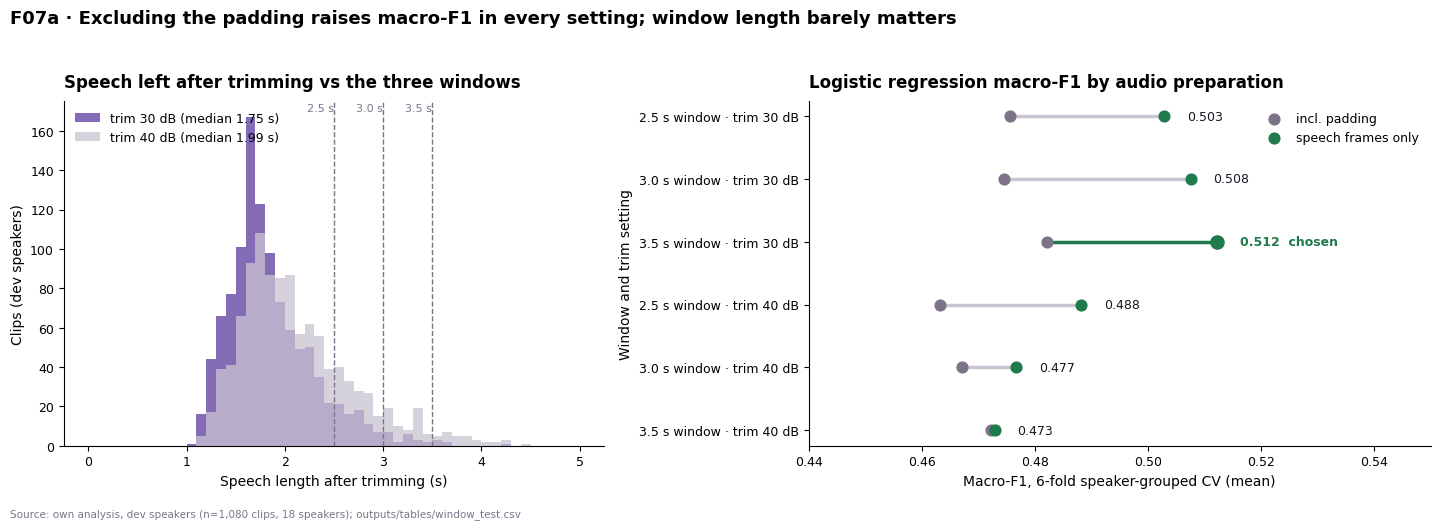

In [6]:
# F07a. Left: how much speech is left after each trim. Right: each
# window x trim setting as a dumbbell from padded (grey) to speech-only
# (green); the chosen setting is labelled.
speech_by_db = {}
for db in TOP_DBS:
    lengths = []
    for rel in index.loc[dev, "filepath"]:
        x, rate, ch = U.read_wav(U.project_root() / rel)
        mono = U.resample_48k_to_16k(U.to_mono(x, ch))
        lengths.append(len(U.trim_silence(mono, top_db=db)[0])
                       / U.TARGET_RATE)
    speech_by_db[db] = np.array(lengths)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2),
                         gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
bins = np.linspace(0, 5, 51)
for (db, s), col in zip(speech_by_db.items(), ["#5B3A9E", U.MUTED]):
    ax.hist(s, bins=bins, alpha=0.75, color=col,
            label=f"trim {int(db)} dB (median {np.median(s):.2f} s)")
for w in WINDOWS:
    ax.axvline(w, color=U.GREY, ls="--", lw=1)
    ax.text(w, ax.get_ylim()[1] * 0.97, f"{w} s", fontsize=8, ha="right",
            color=U.GREY)
U.finish_axes(ax, "Speech left after trimming vs the three windows",
              "Speech length after trimming (s)", "Clips (dev speakers)",
              source="", legend=True)

ax = axes[1]
settings = pad_rows.index.tolist()[::-1]
for i, (w, db) in enumerate(settings):
    a = pad_rows.loc[(w, db), "logreg_macro_f1_mean"]
    b = spc_rows.loc[(w, db), "logreg_macro_f1_mean"]
    chosen = (w, db) == (U.CLIP_SECONDS, int(U.TRIM_TOP_DB))
    ax.plot([a, b], [i, i], color=U.GOOD if chosen else U.MUTED, lw=2.5,
            zorder=1)
    ax.scatter(a, i, s=60, color=U.GREY, zorder=2,
               label="incl. padding" if i == 0 else None)
    ax.scatter(b, i, s=90 if chosen else 60, color=U.GOOD, zorder=3,
               label="speech frames only" if i == 0 else None)
    ax.text(b + 0.004, i, f"{b:.3f}" + ("  chosen" if chosen else ""),
            va="center", fontsize=9, color=U.GOOD if chosen else U.INK,
            fontweight="600" if chosen else "normal")
ax.set_yticks(range(len(settings)))
ax.set_yticklabels([f"{w} s window · trim {db} dB" for w, db in settings])
ax.set_xlim(0.44, 0.55)
U.finish_axes(ax, "Logistic regression macro-F1 by audio preparation",
              "Macro-F1, 6-fold speaker-grouped CV (mean)",
              "Window and trim setting", source="", legend=True)
fig.suptitle("F07a · Excluding the padding raises macro-F1 in every "
             "setting; window length barely matters",
             fontsize=13, fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, DEV_SOURCE + "; outputs/tables/window_test.csv",
         fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
U.save_figure(fig, "F07a_window_trim_ablation.png")
plt.show()

**Verdict: supported. [EVIDENCE]** Computing MFCC and spectral statistics over **speech frames only** beats the
padded version in all 6 settings, for both models. At the chosen 3.5 s / 30 dB setting, logistic regression rises from
0.482 to 0.512 macro-F1 and the SVM from 0.434 to 0.481. The gains are printed above.

**So we** compute MFCC and spectral statistics over speech frames only. The waveform cache keeps its fixed 3.5 s
window for models that need equal-length input; only the statistics skip the padding.

### H13 · A 30 dB trim cuts real speech (40 dB would score better)

**Why it matters:** a stricter trim removes more silence but may also clip soft onsets and endings, the breathy
starts that can signal fear or surprise. If 30 dB were cutting real speech, the gentler 40 dB trim should score
higher.

In [7]:
# 30 dB against 40 dB, for every window x statistics setting.
t30 = grid[grid.top_db == 30].set_index(["window_s", "stats_over"])
t40 = grid[grid.top_db == 40].set_index(["window_s", "stats_over"])
h13 = pd.DataFrame({f"{m} {db} dB": t[f"{m}_macro_f1_mean"]
                    for m in MODELS for db, t in ((30, t30), (40, t40))})
print(h13.to_string())
wins30 = {m: int((h13[f"{m} 30 dB"] > h13[f"{m} 40 dB"]).sum())
          for m in MODELS}
print(f"\n30 dB wins: logreg {wins30['logreg']}/6, svc {wins30['svc']}/6")
print(f"median speech kept: 30 dB {np.median(speech_by_db[30.0]):.2f} s, "
      f"40 dB {np.median(speech_by_db[40.0]):.2f} s")
record("H13", "A 30 dB trim cuts real speech (40 dB would score better)",
       "not supported" if min(wins30.values()) >= 5 else "supported",
       "F07a, window_test.csv", "Keep the 30 dB trim")

                               logreg 30 dB  logreg 40 dB  svc 30 dB  svc 40 dB
window_s stats_over                                                            
2.5      window incl. padding        0.4756        0.4633     0.4183     0.4351
         speech only                 0.5029        0.4882     0.4809     0.4500
3.0      window incl. padding        0.4746        0.4672     0.4316     0.4241
         speech only                 0.5076        0.4767     0.4817     0.4574
3.5      window incl. padding        0.4822        0.4722     0.4336     0.4335
         speech only                 0.5123        0.4729     0.4813     0.4591

30 dB wins: logreg 6/6, svc 5/6
median speech kept: 30 dB 1.75 s, 40 dB 1.99 s

H13 · A 30 dB trim cuts real speech (40 dB would score better)
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** The 30 dB trim scores higher than 40 dB in 6 of 6 settings for logistic
regression and 5 of 6 for the SVM. The one exception is the padded 2.5 s window, which is not a setting we would use.
The extra 0.24 s of "speech" that 40 dB keeps is mostly low-level sound, not signal.

**So we** keep the 30 dB trim.

### H14 · A longer window helps once padding is excluded

**Why it matters:** a shorter window would crop more clips; a longer one pads more. With padding kept out of the
statistics, the only effect left should be cropping.

In [8]:
# Speech-only statistics, 30 dB trim: the three window lengths.
best = grid[(grid.stats_over == "speech only") & (grid.top_db == 30)]
cols_show = ["window_s", "clips_cropped", "pct_cropped",
             "logreg_macro_f1_mean", "logreg_macro_f1_sd",
             "svc_macro_f1_mean", "svc_macro_f1_sd"]
print(best[cols_show].to_string(index=False))
spread = best["logreg_macro_f1_mean"].max() - best[
    "logreg_macro_f1_mean"].min()
sd_min = best["logreg_macro_f1_sd"].min()
print(f"\nlogreg spread across windows {spread:.3f} vs smallest fold "
      f"SD {sd_min:.3f}")
record("H14", "A longer window helps once padding is excluded",
       "not supported" if spread < sd_min else "supported",
       "F07a, window_test.csv",
       f"Keep {U.CLIP_SECONDS} s (crops the fewest clips)")

 window_s  clips_cropped  pct_cropped  logreg_macro_f1_mean  logreg_macro_f1_sd  svc_macro_f1_mean  svc_macro_f1_sd
      2.5             99          9.2                0.5029              0.0359             0.4809           0.0460
      3.0             25          2.3                0.5076              0.0542             0.4817           0.0495
      3.5              6          0.6                0.5123              0.0457             0.4813           0.0521

logreg spread across windows 0.009 vs smallest fold SD 0.036

H14 · A longer window helps once padding is excluded
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** With speech-only statistics, logistic regression scores 0.503, 0.508 and
0.512 for 2.5, 3.0 and 3.5 s. The whole spread is smaller than one fold SD. The SVM is flat.

**So we** keep the **3.5 s window**. It performs as well as the others and crops the fewest clips: 6 of 1,080 dev
clips (0.6%).

**The locked recipe:** 3.5 s window, 30 dB trim, MFCC/spectral statistics over speech frames only. This is the
configuration `features.parquet` was built with (see `feature_manifest.json`, printed in §1).

---
## 3 · What do the features carry?

The locked feature table is now examined as a whole: which groups carry emotion, which carry the speaker, how much
they overlap, and whether the hardest emotion pairs are separable at all.

In [9]:
# The dev matrix of the locked feature table, used by every cell below.
X, y, g, cols = dev_matrix(feats)
print(f"X: {X.shape[0]:,} dev clips x {X.shape[1]} features, "
      f"{np.isnan(X).sum()} missing values")

X: 1,080 dev clips x 512 features, 46 missing values


### H15 · Energy features carry emotion; MFCCs carry the speaker

**Why it matters:** H11 found this for two measures. If it holds across all 512 features, most of the table (the
480 MFCC columns) mainly describes *who* is talking. A model trained on it would struggle on new speakers.

Same measure as in `01_EDA`: η², the share of each feature's variance explained by emotion and, separately, by the
speaker.

In [10]:
# Eta squared of every feature against emotion and against speaker.
def eta_squared(x, labels):
    '''Between-group sum of squares / total sum of squares.'''
    x = np.asarray(x, float)
    ok = np.isfinite(x)
    x, labels = x[ok], labels[ok]
    if x.size < 3 or np.var(x) == 0:
        return np.nan
    grand = x.mean()
    ss_tot = ((x - grand) ** 2).sum()
    ss_b = sum(((x[labels == k].mean() - grand) ** 2)
               * (labels == k).sum() for k in np.unique(labels))
    return float(ss_b / ss_tot)


eta = pd.DataFrame([{"feature": c, "group": F.feature_group(c),
                     "eta2_emotion": eta_squared(X[:, j], y),
                     "eta2_speaker": eta_squared(X[:, j], g)}
                    for j, c in enumerate(cols)])
eta.to_csv(U.tables_dir() / "eta_squared.csv", index=False)
by_group = (eta.groupby("group")[["eta2_emotion", "eta2_speaker"]].median()
            .assign(n_features=eta.groupby("group").size(),
                    share_emotion_gt_speaker=eta.assign(
                        w=eta.eta2_emotion > eta.eta2_speaker)
                    .groupby("group")["w"].mean().round(3))
            .round(4))
by_group.to_csv(U.tables_dir() / "eta_by_group.csv")
by_group

,eta2_emotion,eta2_speaker,n_features,share_emotion_gt_speaker
group,,,,
energy,0.3413,0.0426,5,1.000
mfcc,0.0476,0.1697,480,0.112
pitch,0.1182,0.0000,5,0.800
spectral,0.1146,0.2058,20,0.150
voice_quality,0.1779,0.1356,2,0.500


saved EDA and Feature engineering/outputs/figures/F07b_eta_squared_by_feature.png


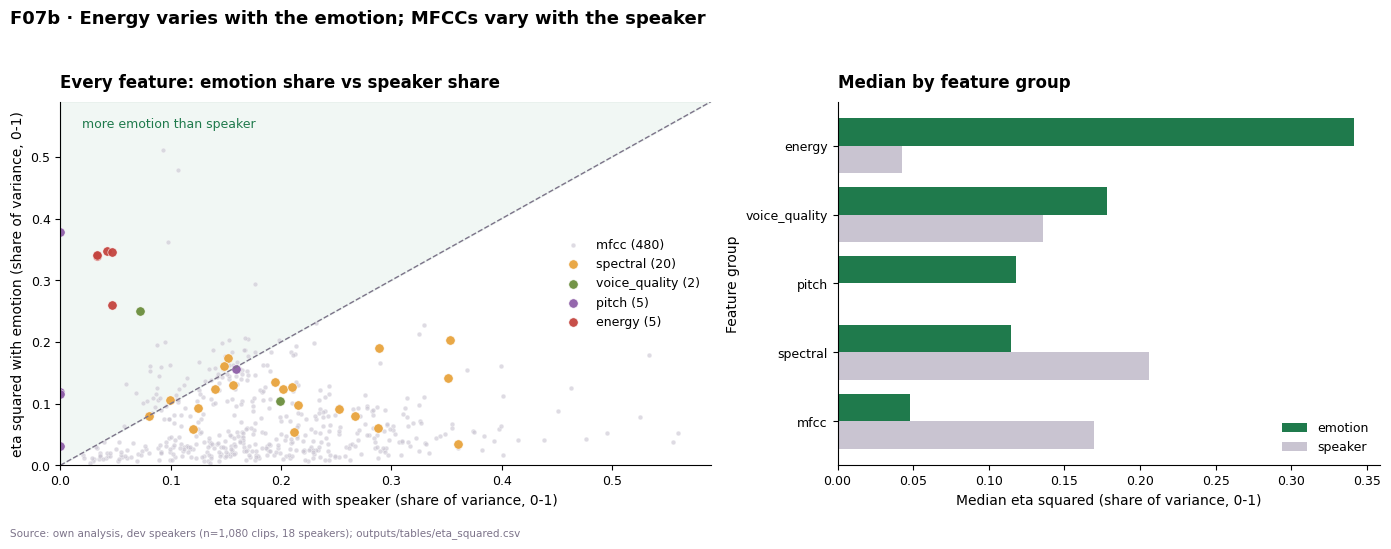

energy: emotion 0.34 vs speaker 0.04; MFCC: emotion 0.05 vs speaker 0.17; MFCC columns leaning to emotion: 11%

H15 · Energy features carry emotion; MFCCs carry the speaker
    verdict: SUPPORTED


In [11]:
# F07b. Left: every feature as a point, emotion eta2 against speaker
# eta2; above the diagonal = more emotion than speaker. Energy is
# highlighted, MFCCs muted. Right: medians by group.
gcol = {"energy": U.EMOTION_COLORS["angry"], "pitch": "#8E5FA8",
        "voice_quality": "#6B8E3D", "spectral": "#E8A33D",
        "mfcc": U.MUTED}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4),
                         gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
lim = float(np.nanmax(eta[["eta2_speaker", "eta2_emotion"]].values)) + 0.03
ax.fill_between([0, lim], [0, lim], lim, color=U.GOOD, alpha=0.06)
ax.text(0.02, lim * 0.93, "more emotion than speaker", fontsize=9,
        color=U.GOOD)
ax.plot([0, lim], [0, lim], color=U.GREY, ls="--", lw=1)
for grp in ["mfcc", "spectral", "voice_quality", "pitch", "energy"]:
    sub = eta[eta.group == grp]
    ax.scatter(sub.eta2_speaker, sub.eta2_emotion,
               s=12 if grp == "mfcc" else 45,
               alpha=0.6 if grp == "mfcc" else 0.95, color=gcol[grp],
               edgecolor="white", linewidth=0.4,
               label=f"{grp} ({len(sub)})")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
U.finish_axes(ax, "Every feature: emotion share vs speaker share",
              "eta squared with speaker (share of variance, 0-1)",
              "eta squared with emotion (share of variance, 0-1)",
              source="", legend=True)

ax = axes[1]
order = by_group.sort_values("eta2_emotion").index
yy = np.arange(len(order))
ax.barh(yy + 0.2, by_group.loc[order, "eta2_emotion"], height=0.4,
        color=U.GOOD, label="emotion")
ax.barh(yy - 0.2, by_group.loc[order, "eta2_speaker"], height=0.4,
        color=U.MUTED, label="speaker")
ax.set_yticks(yy)
ax.set_yticklabels(order)
U.finish_axes(ax, "Median by feature group",
              "Median eta squared (share of variance, 0-1)",
              "Feature group", source="", legend=True)
fig.suptitle("F07b · Energy varies with the emotion; MFCCs vary with the "
             "speaker", fontsize=13, fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, DEV_SOURCE + "; outputs/tables/eta_squared.csv",
         fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
U.save_figure(fig, "F07b_eta_squared_by_feature.png")
plt.show()

en, mf = by_group.loc["energy"], by_group.loc["mfcc"]
print(f"energy: emotion {en.eta2_emotion:.2f} vs speaker "
      f"{en.eta2_speaker:.2f}; MFCC: emotion {mf.eta2_emotion:.2f} vs "
      f"speaker {mf.eta2_speaker:.2f}; MFCC columns leaning to emotion: "
      f"{mf.share_emotion_gt_speaker * 100:.0f}%")
record("H15", "Energy features carry emotion; MFCCs carry the speaker",
       "supported" if (en.eta2_emotion > en.eta2_speaker and
                       mf.eta2_speaker > mf.eta2_emotion)
       else "not supported", "F07b, eta_by_group.csv",
       "Test per-speaker normalisation and speech encoders in modelling")

**Verdict: supported. [EVIDENCE]**
- **Energy** is an emotion property: median η² of 0.34 for emotion against 0.04 for the speaker. All 5 energy
  columns lean towards emotion.
- **MFCCs** lean towards the speaker: 0.05 against 0.17. Only 11% of the 480 MFCC columns carry more emotion than
  speaker variance.
- **Pitch**, already z-scored per speaker, now carries no speaker variance at all (0.00), which confirms the fix
  from H11.

**So we** accept that most of the table is voice-bound, and the modelling section tests two answers to it:
normalising every feature within each speaker, and pre-trained speech encoders that describe speech in a less
voice-specific way.

### H16 · Clips group by emotion rather than by voice

**Why it matters:** if the clips cluster by speaker, a model's nearest neighbours are clips of the same person, not
the same emotion.

To see the structure, all 512 dimensions are reduced to 50 (PCA) and then projected to 2 (t-SNE). This is done
twice: on the standardised features, and after z-scoring every feature within each speaker. The silhouette score
(−1 to 1; near 0 = no clear clusters) is computed on the 50-dimension PCA space, not on the t-SNE picture.

saved EDA and Feature engineering/outputs/figures/F07_tsne_emotion_vs_speaker.png


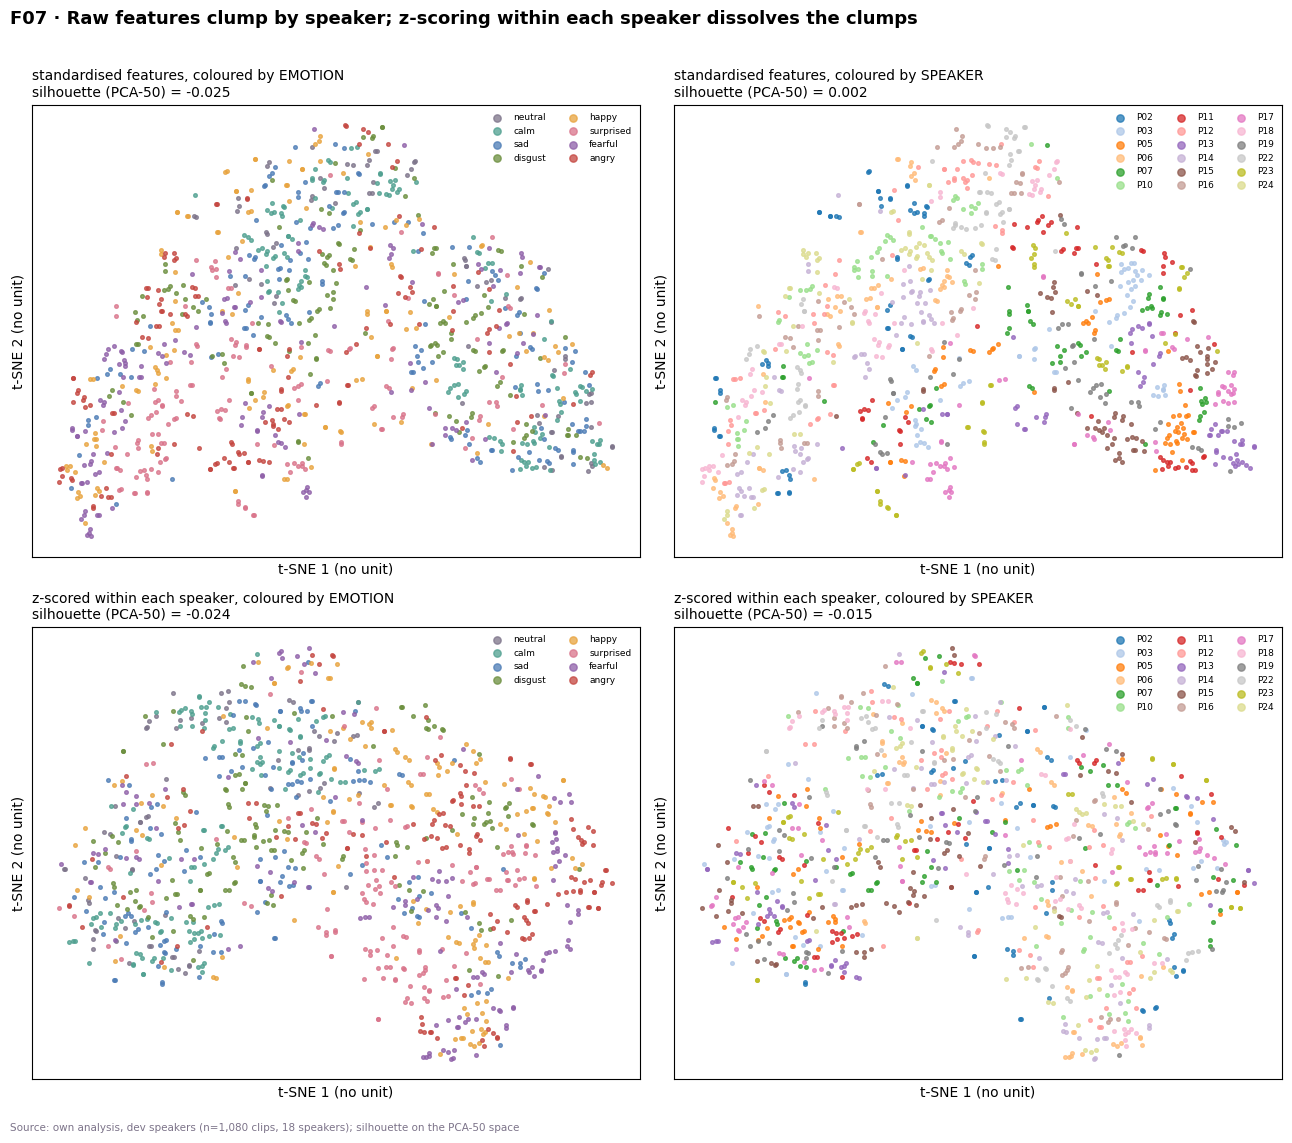

{
  "standardised features": {
    "silhouette_emotion": -0.025,
    "silhouette_speaker": 0.0015
  },
  "z-scored within each speaker": {
    "silhouette_emotion": -0.0241,
    "silhouette_speaker": -0.0154
  }
}

H16 · Clips group by emotion rather than by voice
    verdict: NOT SUPPORTED


In [12]:
# F07: PCA-50 -> t-SNE, coloured by emotion (left) and speaker
# (right); top row standardised, bottom row z-scored per speaker.
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


def speaker_zscore(M, groups):
    '''z-score every column within each speaker (uses no labels).'''
    out = np.empty_like(M)
    for s in np.unique(groups):
        m = groups == s
        sd = np.nanstd(M[m], axis=0)
        sd[sd == 0] = 1.0
        out[m] = (M[m] - np.nanmean(M[m], axis=0)) / sd
    return out


X0 = np.nan_to_num(X)
views = {"standardised features": StandardScaler().fit_transform(X0),
         "z-scored within each speaker": np.nan_to_num(
             speaker_zscore(X0, g))}
silhouette = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 11.5))
cmap = plt.get_cmap("tab20")
for r, (name, Z) in enumerate(views.items()):
    P = PCA(n_components=50, random_state=U.SEED).fit_transform(Z)
    T = TSNE(n_components=2, perplexity=30, random_state=U.SEED,
             init="pca").fit_transform(P)
    silhouette[name] = {
        "silhouette_emotion": round(float(silhouette_score(P, y)), 4),
        "silhouette_speaker": round(float(silhouette_score(P, g)), 4)}
    colourings = [("emotion", y), ("speaker", g)]
    for c, (label_name, labels) in enumerate(colourings):
        ax = axes[r, c]
        values = U.EMOTION_ORDER if c == 0 else sorted(np.unique(g))
        for i, v in enumerate(values):
            m = labels == v
            color = (U.EMOTION_COLORS[v] if c == 0
                     else cmap(i % 20))
            ax.scatter(T[m, 0], T[m, 1], s=7, alpha=0.75, color=color,
                       label=v if c == 0 else f"P{v:02d}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("t-SNE 1 (no unit)")
        ax.set_ylabel("t-SNE 2 (no unit)")
        sil = silhouette[name][f"silhouette_{label_name}"]
        ax.set_title(f"{name}, coloured by {label_name.upper()}\n"
                     f"silhouette (PCA-50) = {sil:.3f}", fontsize=10,
                     loc="left")
        ax.legend(fontsize=6.5, markerscale=2, frameon=False,
                  ncol=2 if c == 0 else 3)
fig.suptitle("F07 · Raw features clump by speaker; z-scoring within each "
             "speaker dissolves the clumps", fontsize=13,
             fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, DEV_SOURCE + "; silhouette on the PCA-50 space",
         fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.02, 1, 0.97])
U.save_figure(fig, "F07_tsne_emotion_vs_speaker.png")
plt.show()

with open(U.tables_dir() / "silhouette.json", "w") as f:
    json.dump(silhouette, f, indent=2)
print(json.dumps(silhouette, indent=2))
record("H16", "Clips group by emotion rather than by voice",
       "not supported", "F07, silhouette.json",
       "Treat the speaker effect as real; do not quote the silhouette as "
       "separation")

**Verdict: not supported. [EVIDENCE]**
- On the standardised features the picture shows **clumps of single speakers** (top right). Emotion appears only as
  a loose gradient from low to high arousal (top left).
- After z-scoring within each speaker, the speaker clumps dissolve and the arousal gradient is easier to see (bottom
  row).
- The silhouette scores are close to zero in every view. The effect is visual, not a strong cluster statistic.

**So we** treat the speaker effect as real, which is why the modelling section tests per-speaker normalisation. We
do not quote the silhouette as evidence that emotions separate.

### H17 · Many features repeat each other

**Why it matters:** strongly correlated columns inflate a model's variance. They also make single-column importance
misleading, because credit gets split between near-copies.

In [13]:
# Pairs of features whose absolute correlation exceeds 0.9 (and 0.8).
C = pd.DataFrame(np.nan_to_num(X), columns=cols).corr().abs().values
iu = np.triu_indices_from(C, 1)
r = C[iu]
redundancy = {
    "n_features": len(cols), "n_pairs": int(r.size),
    "pairs_abs_r_gt_0.9": int((r > 0.9).sum()),
    "pairs_abs_r_gt_0.8": int((r > 0.8).sum()),
    "features_with_a_partner_gt_0.9": int(((C > 0.9).sum(axis=1) - 1
                                           > 0).sum()),
}
with open(U.tables_dir() / "redundancy.json", "w") as f:
    json.dump(redundancy, f, indent=2)
print(json.dumps(redundancy, indent=2))
record("H17", "Many features repeat each other",
       "supported" if redundancy["pairs_abs_r_gt_0.9"] > 0
       else "not supported", "redundancy.json",
       "Use regularised models; report importance by feature group")

{
  "n_features": 512,
  "n_pairs": 130816,
  "pairs_abs_r_gt_0.9": 106,
  "pairs_abs_r_gt_0.8": 707,
  "features_with_a_partner_gt_0.9": 144
}

H17 · Many features repeat each other
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** 106 feature pairs are correlated above |r| = 0.9, and 144 of the 512 features
have at least one such near-copy.

**So we** use regularised models (logistic regression with a tuned penalty, which shrinks near-copies together), and
report feature importance **by group**, not by single column.

### H18 · Emotions that sound alike cannot be told apart

**Why it matters:** `01_EDA` showed that calm, sad and neutral sit close together on loudness and pitch, and so do
surprised and fearful (F05, `emotion_profile.csv`). If these pairs overlap completely in the features, no model
built on them can separate them, and a richer representation would be needed.

**Test:** for each pair, a simple linear classifier (standardise → PCA to 40 dimensions → linear discriminant
analysis) is trained under the same 6-fold speaker-grouped CV. We score it on the held-out speakers of each fold by
**AUC**: 0.5 = no better than chance, 1.0 = perfectly separable.

In [14]:
# Out-of-fold separability of each similar-sounding pair.
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline

PAIRS = [("calm", "sad"), ("neutral", "sad"), ("neutral", "calm"),
         ("surprised", "fearful")]
j_e, j_p = cols.index("energy_rms"), cols.index("f0_mean_speaker_z")
pair_rows, oof_scores = [], {}
for a, b in PAIRS:
    m = np.isin(y, [a, b])
    Xp, yp, gp = X0[m], (y[m] == b).astype(int), g[m]
    oof = np.zeros(len(yp))
    for tr, va in GroupKFold(6).split(Xp, yp, gp):
        # PCA inside the fold keeps LDA stable with 512 features and a
        # few hundred clips.
        pipe = make_pipeline(StandardScaler(),
                             PCA(n_components=40, random_state=U.SEED),
                             LinearDiscriminantAnalysis())
        pipe.fit(Xp[tr], yp[tr])
        oof[va] = pipe.decision_function(Xp[va])
    oof_scores[(a, b)] = (oof, yp, m)
    pair_rows.append({
        "pair": f"{a} vs {b}", "n": int(m.sum()),
        "oof_auc": round(roc_auc_score(yp, oof), 4),
        "oof_accuracy": round(float(((oof > 0) == yp).mean()), 4),
        f"energy_median_{a}": round(float(np.median(X0[y == a, j_e])), 5),
        f"energy_median_{b}": round(float(np.median(X0[y == b, j_e])), 5)})
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(U.tables_dir() / "confusion_pairs.csv", index=False)
pairs[["pair", "n", "oof_auc", "oof_accuracy"]]

,pair,n,oof_auc,oof_accuracy
0,calm vs sad,288,0.7977,0.7396
1,neutral vs sad,216,0.7318,0.7130
2,neutral vs calm,216,0.7430,0.7176
3,surprised vs fearful,288,0.8317,0.7674


saved EDA and Feature engineering/outputs/figures/F07c_confusion_pairs.png


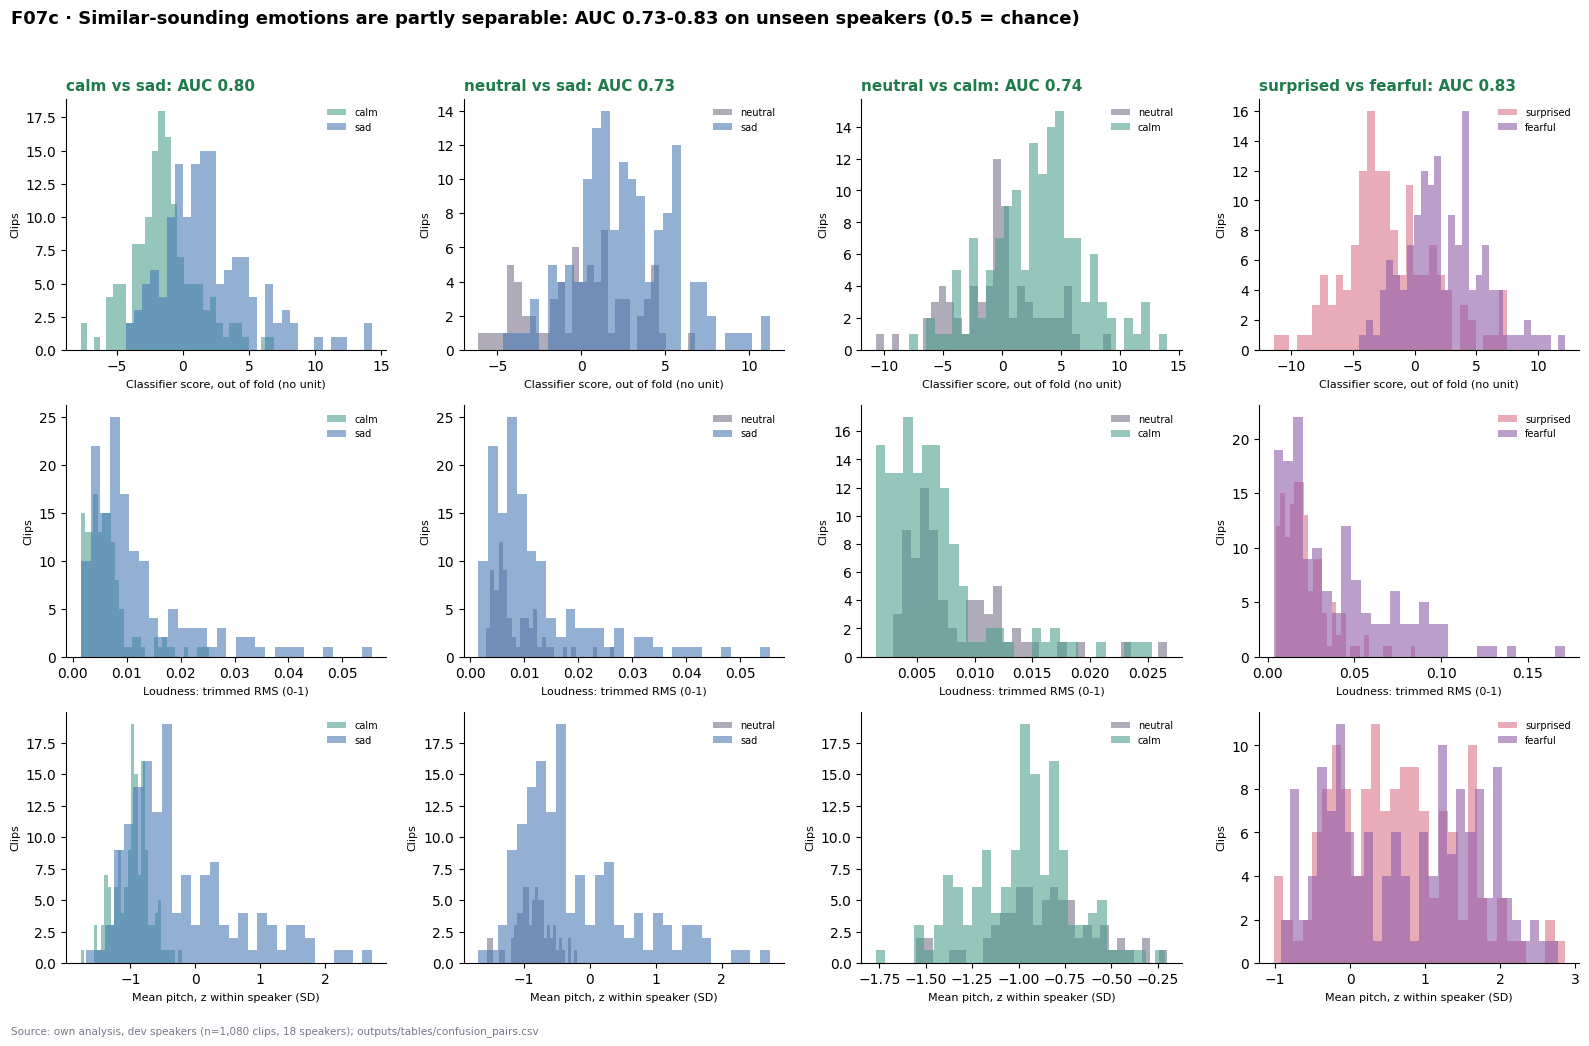


H18 · Emotions that sound alike cannot be told apart
    verdict: NOT SUPPORTED


In [15]:
# F07c. Top row: the classifier's out-of-fold score for each pair,
# with the AUC in the panel title (the inference). Rows 2-3: energy and
# per-speaker pitch, to show where the overlap comes from.
fig, axes = plt.subplots(3, len(PAIRS), figsize=(16, 10.5))
for c, (a, b) in enumerate(PAIRS):
    oof, yp, m = oof_scores[(a, b)]
    auc = pairs.loc[c, "oof_auc"]
    panels = [(oof, "Classifier score, out of fold (no unit)"),
              (X0[m, j_e], "Loudness: trimmed RMS (0-1)"),
              (X0[m, j_p], "Mean pitch, z within speaker (SD)")]
    for r, (vals, xlabel) in enumerate(panels):
        ax = axes[r, c]
        for lab, e in [(0, a), (1, b)]:
            ax.hist(vals[yp == lab], bins=30, alpha=0.6,
                    color=U.EMOTION_COLORS[e], label=e)
        if r == 0:
            ax.set_title(f"{a} vs {b}: AUC {auc:.2f}", fontsize=11,
                         loc="left", fontweight="600",
                         color=U.GOOD if auc > 0.6 else U.ACCENT)
        ax.set_xlabel(xlabel, fontsize=8)
        ax.set_ylabel("Clips", fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=7, frameon=False)
lo_auc, hi_auc = pairs["oof_auc"].min(), pairs["oof_auc"].max()
fig.suptitle(f"F07c · Similar-sounding emotions are partly separable: "
             f"AUC {lo_auc:.2f}-{hi_auc:.2f} on unseen speakers (0.5 = "
             "chance)", fontsize=13, fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, DEV_SOURCE + "; outputs/tables/confusion_pairs.csv",
         fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.02, 1, 0.96])
U.save_figure(fig, "F07c_confusion_pairs.png")
plt.show()
record("H18", "Emotions that sound alike cannot be told apart",
       "not supported" if lo_auc > 0.6 else "supported",
       "F07c, confusion_pairs.csv",
       "Expect these pairs to dominate errors; try richer representations")

**Verdict: not supported. [EVIDENCE]** Every pair is separable well above chance on unseen speakers: AUC 0.80 for
calm/sad, 0.73 for neutral/sad, 0.74 for neutral/calm and 0.83 for surprised/fearful. The overlap is large, though;
the distributions in the top row share a wide middle ground. Loudness alone separates calm from sad only partly.

**So we** expect these pairs to account for most of the errors, but they are not hopeless. That makes richer
representations worth trying in the modelling section (a CNN on spectrograms, pre-trained speech encoders).

### H19 · A random split keeps the duplicate pair together

**Why it matters:** H3 found one recording saved twice. If a split puts one copy in training and the other in
validation, the model is scored on audio it has already heard. This is the concrete version of the leakage risk
that drove the speaker split (H6).

In [16]:
# Where do the two identical files land under each kind of split?
audit = pd.read_csv(U.tables_dir() / "audit_report.csv")
dup_fps = audit.loc[audit["is_duplicate"], "filepath"].tolist()
assert len(dup_fps) == 2, "expected exactly one duplicate pair"
dev_fps = index.loc[dev, "filepath"].values
placement = {"pair": dup_fps,
             "unique_waveforms": int(audit["md5"].nunique())}
for split_type in ("grouped", "random"):
    folds = S.outer_splits(split_type, np.zeros((len(dev_fps), 1)), y, g)
    where = {fp: k for k, (_, va) in enumerate(folds)
             for fp in dup_fps if fp in set(dev_fps[va])}
    placement[split_type] = where
    placement[f"{split_type}_same_fold"] = len(set(where.values())) == 1
    verdict = ("together" if placement[f"{split_type}_same_fold"]
               else "APART")
    print(f"{split_type:>7} split: folds {sorted(where.values())} -> "
          f"{verdict}")
with open(U.tables_dir() / "duplicate_check.json", "w") as f:
    json.dump(placement, f, indent=2)
record("H19", "A random split keeps the duplicate pair together",
       "supported" if placement["random_same_fold"] else "not supported",
       "duplicate_check.json",
       "Split by speaker for every result (confirms H6)")

grouped split: folds [1, 1] -> together
 random split: folds [1, 4] -> APART

H19 · A random split keeps the duplicate pair together
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** Under a random split the two identical files land in **different folds** (1
and 4). Whichever fold validates one copy has trained on the other. Under the speaker split they sit in the same fold
automatically, because they belong to the same speaker.

**So we** use the speaker split for every reported result. The random split is kept only to show how much it would
inflate the scores.

---
## 4 · Summary

In [17]:
# All hypotheses tested in this notebook, in order.
summary = pd.DataFrame(SUMMARY).set_index("H")
with pd.option_context("display.max_colwidth", 80):
    display(summary)

,hypothesis,verdict,evidence,so we
H,,,,
H12,Averaging over the padded window dilutes the features,supported,"F07a, window_test.csv",Compute MFCC/spectral statistics over speech frames only
H13,A 30 dB trim cuts real speech (40 dB would score better),not supported,"F07a, window_test.csv",Keep the 30 dB trim
H14,A longer window helps once padding is excluded,not supported,"F07a, window_test.csv",Keep 3.5 s (crops the fewest clips)
H15,Energy features carry emotion; MFCCs carry the speaker,supported,"F07b, eta_by_group.csv",Test per-speaker normalisation and speech encoders in modelling
H16,Clips group by emotion rather than by voice,not supported,"F07, silhouette.json",Treat the speaker effect as real; do not quote the silhouette as separation
H17,Many features repeat each other,supported,redundancy.json,Use regularised models; report importance by feature group
H18,Emotions that sound alike cannot be told apart,not supported,"F07c, confusion_pairs.csv",Expect these pairs to dominate errors; try richer representations
H19,A random split keeps the duplicate pair together,not supported,duplicate_check.json,Split by speaker for every result (confirms H6)


**What this section hands to modelling:**

1. **The feature table:** `outputs/features/features.parquet`, 1,440 rows × 512 features in five groups. It is built
   with a 3.5 s window, a 30 dB trim and statistics over speech frames only (H12–H14). Pitch is z-scored within each
   speaker (H11).
2. **The evaluation rules:** dev speakers only; 6 folds that each hold out whole speakers; the scaler fitted inside
   each fold; macro-F1 as the headline metric (H1, H6, H19).
3. **What to expect:**
   - most of the table is voice-bound (H15, H16), so per-speaker normalisation and speech encoders are worth testing;
   - the features are redundant (H17), so regularised models fit;
   - the similar-sounding pairs will dominate the errors but are partly separable (H18).